# PKU-MMD: K-means и LSTM в непрерывном потоке

Работаем только с действиями одного человека. Исключены группы записей с взаимодействиями двух людей. Остаются 43 действия и фон. Старые результаты для 52 классов неприменимы: нужно заново подготовить данные, обучить модели и получить метрики.


In [39]:
from pathlib import Path
from itertools import product
import importlib
import re
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import IncrementalPCA
from sklearn.metrics import f1_score
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if not (ROOT / "comparison_methods.py").is_file():
    ROOT = ROOT / "Unitree_g1_causal_command_segmentation"
if not (ROOT / "comparison_methods.py").is_file():
    raise FileNotFoundError("Откройте ноутбук из папки проекта или задайте ROOT вручную.")

sys.path.insert(0, str(ROOT))
importlib.invalidate_caches()
import constants
constants = importlib.reload(constants)
import comparison_methods as cm
cm = importlib.reload(cm)

DATA = ROOT / "dataset" / "PKU_MMD"
SKELETON_DIR = DATA / "Skeleton"
LABEL_DIR = DATA / "Label"

SEED = 42
SAMPLE_HZ = 30
WINDOW = 30
STRIDE = 2
DT = STRIDE / SAMPLE_HZ
N_COMPONENTS = 16
SPLIT_FRACTIONS = {"train": 0.6, "conf": 0.2, "test": 0.2}
SPLIT_ATTEMPTS = 512

# В скачанной разметке есть кадр 0 и соседние интервалы с общей границей.
# Используем нулевую индексацию. Начало включаем, конец не включаем.
LABEL_INDEX_BASE = 0
LABEL_END_INCLUSIVE = False

# Исключаем только известную повреждённую запись, исходные файлы не меняем.
EXCLUDED_RECORDS = {
    "0043-L": "неверный интервал класса 1: начало 4925, конец 4036",
}

# Исходные номера PKU-MMD начинаются с 1.
ORIGINAL_ACTION_IDS = np.arange(1, 52, dtype=int)
INTERACTION_CLASSES = {
    12: "giving something to other person",
    14: "handshaking",
    16: "hugging other person",
    18: "kicking other person",
    21: "pat on back of other person",
    24: "point finger at the other person",
    26: "punching/slapping other person",
    27: "pushing other person",
}
SINGLE_PERSON_ACTION_IDS = tuple(
    int(i) for i in ORIGINAL_ACTION_IDS if i not in INTERACTION_CLASSES
)
BACKGROUND_ID = 0
ORIGINAL_TO_CLASS = {0: BACKGROUND_ID}
ORIGINAL_TO_CLASS.update({original: i for i, original in enumerate(SINGLE_PERSON_ACTION_IDS, 1)})
CLASS_TO_ORIGINAL = {label: original for original, label in ORIGINAL_TO_CLASS.items()}
CLASS_IDS = np.arange(len(ORIGINAL_TO_CLASS), dtype=int)
ACTION_IDS = CLASS_IDS[1:]
LABEL_NAMES = {0: "BACKGROUND", **{
    label: f"action_{original:02d}" for label, original in CLASS_TO_ORIGINAL.items() if label
}}
assert len(ACTION_IDS) == 43

MAJORITY_WINDOWS = tuple(cm.MAJORITY_WINDOWS)
CONFIRMATION_WINDOWS = tuple(cm.CONFIRMATION_WINDOWS)
CONFIDENCE_THRESHOLDS = tuple(cm.CONFIDENCE_THRESHOLDS)

FSM_PARAMS = dict(
    neutral_id=BACKGROUND_ID,
    distractor_id=BACKGROUND_ID,
    label_names=LABEL_NAMES,
)
METRIC_PARAMS = dict(
    active_command_ids=ACTION_IDS,
    window_step_seconds=DT,
    iou_threshold=0.50,
    f1_iou_thresholds=(0.10, 0.25, 0.50),
)

assert WINDOW >= 2 and 0 < STRIDE <= WINDOW
assert LABEL_INDEX_BASE in (0, 1)
assert np.isclose(sum(SPLIT_FRACTIONS.values()), 1.0)


## Чтение записей и проверка разметки

Удаляем целиком группы ракурсов, если хотя бы в одном есть взаимодействие двух людей. Эти действия не превращаем в фон и не вырезаем из середины последовательностей. Исходные номера оставшихся классов сохраняются в CLASS_TO_ORIGINAL, для моделей используются непрерывные индексы 0–43.

В [статье авторов, таблица 3](https://www.icst.pku.edu.cn/struct/Pub%20Files/2017/lch_mm17.pdf) указано 8 взаимодействий. Нумерация сверена со [списком PKU-MMD в коде SA-DVAE](https://github.com/pha123661/SA-DVAE/blob/eccv-camera-ready/class_lists/pku51.csv), где индексы начинаются с 0, и локальными файлами разметки.


In [40]:
def index_files(directory, extensions):
    if not directory.is_dir():
        raise FileNotFoundError(
            f"Нет папки {directory}. Распакуйте PKU-MMD Phase I "
            "и проверьте SKELETON_DIR и LABEL_DIR."
        )

    indexed = {}
    for path in sorted(directory.rglob("*")):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue
        if not re.fullmatch(r"\d+-[LMR]", path.stem, flags=re.IGNORECASE):
            continue

        record_id = path.stem.upper()
        if record_id in indexed:
            raise ValueError(f"Две версии записи {record_id}: {indexed[record_id]} и {path}")
        indexed[record_id] = path

    if not indexed:
        raise ValueError(f"В {directory} нет файлов вида 0001-L с нужным расширением.")
    return indexed


def read_annotations(path):
    rows = []
    with path.open(encoding="utf-8-sig") as stream:
        for line_number, line in enumerate(stream, start=1):
            if not line.strip():
                continue
            values = re.split(r"[,\s]+", line.strip())
            if len(values) != 4:
                raise ValueError(f"{path.name}, строка {line_number}: ожидаются четыре числа.")

            try:
                row = tuple(int(value) for value in values)
            except ValueError as error:
                raise ValueError(f"{path.name}: в разметке нужны целые числа.") from error
            label, start, end, quality = row
            if label not in ORIGINAL_ACTION_IDS or quality not in (0, 1, 2):
                raise ValueError(f"{path.name}: неизвестный класс или качество аннотации {row}.")
            rows.append(row)

    if not rows:
        raise ValueError(f"Пустая разметка: {path}")
    return np.asarray(rows, dtype=np.int64)


def frame_targets(annotations, n_frames, record_id):
    target = np.full(n_frames, BACKGROUND_ID, dtype=np.int64)
    for label, start, end, quality in annotations:
        left = int(start) - LABEL_INDEX_BASE
        right = int(end) - LABEL_INDEX_BASE + int(LABEL_END_INCLUSIVE)
        if not 0 <= left < right <= n_frames:
            raise ValueError(
                f"{record_id}: интервал [{start}, {end}], кадров {n_frames}. "
                "Проверьте базу индексов и включение правой границы."
            )

        if label not in ORIGINAL_TO_CLASS:
            raise ValueError(f"{record_id}: взаимодействие попало в одночеловеческую выборку.")
        label = ORIGINAL_TO_CLASS[int(label)]
        previous = target[left:right]
        if np.any((previous != BACKGROUND_ID) & (previous != label)):
            raise ValueError(f"{record_id}: пересечение разных действий на [{start}, {end}].")
        target[left:right] = label

    return target


def make_inventory():
    skeletons = index_files(SKELETON_DIR, {".skeleton", ".txt"})
    labels = index_files(LABEL_DIR, {".label", ".txt"})
    if set(skeletons) != set(labels):
        missing_labels = sorted(set(skeletons) - set(labels))
        missing_skeletons = sorted(set(labels) - set(skeletons))
        raise ValueError(
            f"Не совпадают пары файлов. Нет меток: {missing_labels[:10]}. "
            f"Нет скелетов: {missing_skeletons[:10]}."
        )

    annotations_by_record = {
        record_id: read_annotations(path) for record_id, path in labels.items()
    }
    interaction_groups = {
        int(record_id.split("-")[0])
        for record_id, annotations in annotations_by_record.items()
        if any(int(label) in INTERACTION_CLASSES for label in annotations[:, 0])
    }
    excluded = sum(int(record_id.split("-")[0]) in interaction_groups for record_id in skeletons)
    print(f"Исключены взаимодействия: {len(interaction_groups)} групп, {excluded} записей.")

    records = []
    for record_id, path in skeletons.items():
        if int(record_id.split("-")[0]) in interaction_groups:
            continue
        if record_id in EXCLUDED_RECORDS:
            print(f"Исключена запись {record_id}: {EXCLUDED_RECORDS[record_id]}.")
            continue

        with path.open() as stream:
            n_frames = sum(bool(line.strip()) for line in stream)
        if n_frames < WINDOW:
            raise ValueError(f"{record_id}: запись короче окна, автоматически её не исключаем.")

        annotations = annotations_by_record[record_id]
        target = frame_targets(annotations, n_frames, record_id)
        ends = np.arange(WINDOW - 1, n_frames, STRIDE)
        counts = np.bincount(target[ends], minlength=len(CLASS_IDS))
        missed_intervals = sum(
            not np.any(
                (ends >= start - LABEL_INDEX_BASE)
                & (ends < end - LABEL_INDEX_BASE + int(LABEL_END_INCLUSIVE))
            )
            for _, start, end, _ in annotations
        )
        records.append(dict(
            record_id=record_id,
            group=int(record_id.split("-")[0]),
            view=record_id.rsplit("-", 1)[1],
            path=path,
            label_path=labels[record_id],
            n_frames=n_frames,
            annotations=annotations,
            counts=counts,
            missed_intervals=missed_intervals,
        ))

    if not records:
        raise ValueError("После исключений не осталось записей для анализа.")
    return records


inventory = make_inventory()
available = set(np.flatnonzero(np.sum([r["counts"] for r in inventory], axis=0)))
if available != set(CLASS_IDS):
    raise ValueError(
        f"Ожидались все {len(CLASS_IDS)} класса на сетке окон. Нет классов: {sorted(set(CLASS_IDS) - available)}. "
        "Проверьте полноту Phase I и размер шага."
    )

print(f"Записей: {len(inventory)}. Групп ракурсов: {len({r['group'] for r in inventory})}.")
print(f"Интервалов без единого конца окна: {sum(r['missed_intervals'] for r in inventory)}.")
display(pd.DataFrame([
    {"class_id": i, "class": LABEL_NAMES[i],
     "records": sum(r["counts"][i] > 0 for r in inventory),
     "groups": len({r["group"] for r in inventory if r["counts"][i] > 0})}
    for i in CLASS_IDS
]))


Исключены взаимодействия: 74 групп, 222 записей.
Исключена запись 0043-L: неверный интервал класса 1: начало 4925, конец 4036.
Записей: 853. Групп ракурсов: 285.
Интервалов без единого конца окна: 4.


,class_id,class,records,groups
0,0,BACKGROUND,853,285
1,1,action_01,398,133
2,2,action_02,458,153
3,3,action_03,419,140
4,4,action_04,422,141
5,5,action_05,416,139
6,6,action_06,425,142
7,7,action_07,419,140
8,8,action_08,443,148
9,9,action_09,422,141


## Разбиение train / conf / test

Используем все найденные записи, кроме явно исключённых. Объединяем оставшиеся ракурсы с одним номером в неделимую группу. Перебираем воспроизводимые варианты разбиения 60/20/20 и выбираем вариант с покрытием всех классов и близкими долями окон каждого класса.

Одинаковые train, conf и test используются для K-means и LSTM.


In [41]:
def balanced_split(records):
    groups = sorted({r["group"] for r in records})
    if len(groups) < 6:
        raise ValueError("Слишком мало независимых групп для трёх выборок.")

    group_counts = np.stack([
        np.sum([r["counts"] for r in records if r["group"] == group], axis=0)
        for group in groups
    ])
    coverage = (group_counts > 0).sum(axis=0)
    if np.any(coverage < 3):
        rare = CLASS_IDS[coverage < 3].tolist()
        raise ValueError(f"Классы {rare} встречаются менее чем в трёх группах.")

    names = list(SPLIT_FRACTIONS)
    fractions = np.asarray(list(SPLIT_FRACTIONS.values()))
    n_train = int(len(groups) * fractions[0])
    n_conf = int(len(groups) * fractions[1])
    cuts = (n_train, n_train + n_conf)
    total = group_counts.sum(axis=0)
    rng = np.random.default_rng(SEED)
    best, best_score = None, np.inf

    for _ in range(SPLIT_ATTEMPTS):
        parts = np.split(rng.permutation(len(groups)), cuts)
        counts = np.stack([group_counts[part].sum(axis=0) for part in parts])
        if np.any(counts == 0):
            continue

        class_error = np.mean((counts / total - fractions[:, None]) ** 2)
        size_error = np.mean((counts.sum(axis=1) / total.sum() - fractions) ** 2)
        score = class_error + size_error
        if score < best_score:
            best_score = score
            best = {name: {groups[i] for i in part} for name, part in zip(names, parts)}

    if best is None:
        raise ValueError(
            "Не найден вариант со всеми классами. Увеличьте SPLIT_ATTEMPTS "
            "или проверьте число независимых групп, не переносите отдельные окна."
        )

    return {
        name: sorted([r for r in records if r["group"] in group_ids], key=lambda r: r["record_id"])
        for name, group_ids in best.items()
    }


selected = balanced_split(inventory)
group_sets = {name: {r["group"] for r in records} for name, records in selected.items()}
for a, b in (("train", "conf"), ("train", "test"), ("conf", "test")):
    assert group_sets[a].isdisjoint(group_sets[b])
assert sum(map(len, selected.values())) == len(inventory)

split_manifest = pd.DataFrame([
    {"split": name, "record_id": r["record_id"], "group": r["group"], "view": r["view"]}
    for name, records in selected.items() for r in records
])
class_balance = pd.DataFrame(
    {name: np.sum([r["counts"] for r in records], axis=0) for name, records in selected.items()},
    index=pd.Index(CLASS_IDS, name="class_id"),
)
assert (class_balance > 0).all().all()
display(split_manifest.groupby("split").agg(records=("record_id", "size"), groups=("group", "nunique")))
display(class_balance)

,records,groups
split,,
conf,171,57
test,171,57
train,511,171


,train,conf,test
class_id,,,
0,767713,254018,260043
1,6714,2160,2648
2,25552,7460,7927
3,22487,7489,6925
4,12144,4444,4441
5,11372,3904,3658
6,12301,3168,4143
7,11268,3833,4290
8,20466,6864,6248


## Оконные признаки и PCA

Берём один скелет из первого кадра с ненулевым тазом. Если видны оба, выбираем первый слот. До конца записи слот фиксирован. При исчезновении скелета оставляем нули и признак отсутствия, не переключаемся на второго человека и не используем будущие кадры. Центрируем 25 суставов по тазу. Получаем 75 координат и один признак присутствия, после четырёх оконных статистик получаем 304 признака перед PCA. Взаимное положение двух людей не используется.

Как в HuGaDB, для каждого сигнала считаем 1) среднее 2) стандартное отклонение 3) RMS 4) RMS разностей соседних кадров. Окно длится 1 секунду, шаг 0,1 секунды. Целевая метка берётся на **последнем кадре окна**, а не голосованием по будущему.

StandardScaler и PCA обучаются только на train.


In [42]:
def read_record_features(record):
    with record["path"].open() as stream:
        rows = (line.replace(",", " ") for line in stream if line.strip())
        raw = np.loadtxt(rows, dtype=np.float32, ndmin=2)
    if raw.shape != (record["n_frames"], 150) or not np.isfinite(raw).all():
        raise ValueError(f"{record['record_id']}: ожидались конечные координаты размера (T, 150).")

    bodies = raw.reshape(-1, 2, 25, 3)
    # Выбор слота зависит только от первого кадра с видимым скелетом.
    body_slot = None
    for frame in bodies:
        candidates = np.flatnonzero(np.any(frame[:, 0, :] != 0, axis=-1))
        if len(candidates):
            body_slot = int(candidates[0])
            break
    if body_slot is None:
        raise ValueError(f"{record['record_id']}: нет ни одного видимого скелета.")

    body = bodies[:, body_slot]
    joints_present = np.any(body != 0, axis=-1)
    present = joints_present[:, 0]
    local = body - body[:, :1, :]
    local[~(joints_present & present[:, None])] = 0
    signal = np.concatenate(
        [local.reshape(len(raw), 75), present[:, None].astype(np.float32)], axis=1
    )

    starts = np.arange(0, len(signal) - WINDOW + 1, STRIDE)
    stops = starts + WINDOW
    signal64 = signal.astype(np.float64)
    sums = np.vstack([np.zeros((1, signal.shape[1])), np.cumsum(signal64, axis=0)])
    squares = np.vstack([np.zeros((1, signal.shape[1])), np.cumsum(signal64 ** 2, axis=0)])
    mean = (sums[stops] - sums[starts]) / WINDOW
    mean_square = (squares[stops] - squares[starts]) / WINDOW

    # Разности берём только внутри текущего окна.
    diff_squares = np.diff(signal64, axis=0) ** 2
    diff_sums = np.vstack([np.zeros((1, signal.shape[1])), np.cumsum(diff_squares, axis=0)])
    diff_energy = (diff_sums[stops - 1] - diff_sums[starts]) / (WINDOW - 1)
    features = np.concatenate([
        mean,
        np.sqrt(np.maximum(mean_square - mean ** 2, 0)),
        np.sqrt(np.maximum(mean_square, 0)),
        np.sqrt(np.maximum(diff_energy, 0)),
    ], axis=1).astype(np.float32)

    targets = frame_targets(record["annotations"], len(raw), record["record_id"])[stops - 1]
    assert np.isfinite(features).all()
    assert np.array_equal(np.bincount(targets, minlength=len(CLASS_IDS)), record["counts"])
    return features, targets, starts, stops - 1


scaler = StandardScaler()
with threadpool_limits(limits=2):
    for record in selected["train"]:
        features, _, _, _ = read_record_features(record)
        scaler.partial_fit(features)

    pca = IncrementalPCA(n_components=N_COMPONENTS, batch_size=2048)
    pending = []
    pending_size = 0
    for record in selected["train"]:
        features, _, _, _ = read_record_features(record)
        pending.append(scaler.transform(features))
        pending_size += len(features)
        if pending_size >= max(2048, N_COMPONENTS):
            block = np.concatenate(pending)
            # Оставляем хвост, чтобы последний partial_fit получил хотя бы 16 окон.
            if len(block) >= 2048 + N_COMPONENTS:
                pca.partial_fit(block[:-N_COMPONENTS])
                pending = [block[-N_COMPONENTS:]]
                pending_size = N_COMPONENTS

    if pending_size < N_COMPONENTS:
        raise ValueError("Недостаточно train-окон для 16 компонент PCA.")
    pca.partial_fit(np.concatenate(pending))

splits, sequences, slices = {}, {}, {}
with threadpool_limits(limits=2):
    for name, records in selected.items():
        features_parts, target_parts, meta_parts = [], [], []
        for record in records:
            features, target, starts, ends = read_record_features(record)
            pcs = np.ascontiguousarray(pca.transform(scaler.transform(features)), dtype=np.float32)
            features_parts.append(pcs)
            target_parts.append(target)
            meta_parts.append(pd.DataFrame({
                "record_id": record["record_id"],
                "window_start_frame": starts,
                "window_end_frame": ends,
            }))

        X = np.concatenate(features_parts)
        y = np.concatenate(target_parts)
        meta = pd.concat(meta_parts, ignore_index=True)
        splits[name] = (X, y, meta)
        slices[name], _ = cm.record_slices(tuple(meta.record_id.drop_duplicates()), meta)
        sequences[name] = [
            (record["record_id"], X[sl], y[sl])
            for record, sl in zip(records, slices[name])
        ]
        assert set(np.unique(y)) == set(CLASS_IDS)
        print(f"{name}: {len(records)} записей, {len(y)} окон, признаки {X.shape}.")

del features_parts, target_parts, meta_parts, features, pending
print(f"Доля дисперсии в 16 компонентах: {pca.explained_variance_ratio_.sum():.3f}.")


train: 511 записей, 1460587 окон, признаки (1460587, 16).
conf: 171 записей, 485822 окон, признаки (485822, 16).
test: 171 записей, 483055 окон, признаки (483055, 16).
Доля дисперсии в 16 компонентах: 0.769.


## Общие метрики и подбор параметров

Переключатель **M4_SELECTION_MODE** находится в **constants.py**. Сейчас включён **f1**: максимум Event-F1@50, затем минимум ложных активаций, p95 и медианы задержки. Вариант **reliability** сохраняет альтернативное правило ниже.

Для M4 сначала сравниваем лучший Event-F1@50 с максимумом среди M1, выбранного M2 и M3 на conf. Если этот уровень достижим, оставляем варианты M4 не хуже него. Иначе оставляем варианты не ниже 95% лучшего F1 самого M4. Среди допустимых вариантов минимизируем ложные активации, затем двойные команды, p95 и медиану задержки. При полном равенстве выбираем больший F1. Относительный допуск задан в constants.py как M4_F1_TOLERANCE. Правило применяется отдельно для K-means и LSTM. Test не участвует в подборе. После изменения нужно повторить подбор, test-метрики и сводные таблицы.


In [43]:
def filtered(raw, split_name, *, window=None, confidence=None, confirmations=None, threshold=None):
    record_slices = slices[split_name]
    if window is not None:
        return cm.apply_per_record(
            raw, record_slices, lambda x: cm.causal_majority(x, window)
        )[0]

    return cm.apply_per_record(
        raw,
        record_slices,
        lambda x, c: cm.transition_automaton(x, c, confirmations, threshold, **FSM_PARAMS),
        confidence,
    )[0]


def evaluate_prediction(prediction, split_name):
    target = splits[split_name][1]
    assert prediction.shape == target.shape
    assert set(np.unique(prediction)) <= set(CLASS_IDS)
    return {
        **cm.evaluate(target, prediction, slices[split_name], **METRIC_PARAMS),
        "macro_f1": f1_score(target, prediction, labels=CLASS_IDS, average="macro", zero_division=0),
    }


def tune_filters(one, two, confidence):
    rows = []
    for window in MAJORITY_WINDOWS:
        pred = filtered(one, "conf", window=window)
        rows.append(dict(method="M2", window=window, **evaluate_prediction(pred, "conf")))

    for confirmations, threshold in product(CONFIRMATION_WINDOWS, CONFIDENCE_THRESHOLDS):
        pred = filtered(
            two, "conf", confidence=confidence,
            confirmations=confirmations, threshold=threshold,
        )
        rows.append(dict(
            method="M4", confirmations=confirmations, threshold=threshold,
            **evaluate_prediction(pred, "conf"),
        ))

    table = pd.DataFrame(rows)
    chosen = {}
    for method in ("M2", "M4"):
        if method == "M4":
            baseline_f1 = max(
                evaluate_prediction(one, "conf")["event_f1@50"],
                chosen["M2"]["event_f1@50"],
                evaluate_prediction(two, "conf")["event_f1@50"],
            )
            chosen[method] = cm.choose_m4_params(
                table[table.method == method], baseline_f1=baseline_f1,
            )
            continue
        chosen[method] = table[table.method == method].sort_values(
            ["event_f1@50", "false_activations_per_min", "p95_delay_s"],
            ascending=[False, True, True], kind="stable", na_position="last",
        ).iloc[0]

    params = dict(
        window=int(chosen["M2"].window),
        confirmations=int(chosen["M4"].confirmations),
        threshold=float(chosen["M4"].threshold),
    )
    display(pd.DataFrame(chosen).T[
        ["window", "confirmations", "threshold", "event_f1@50", "false_activations_per_min"]
    ].round(3))
    display(chosen["M4"][[
        "conf_baseline_f1@50", "conf_best_m4_f1@50", "conf_min_m4_f1@50", "event_f1@50",
    ]])
    return table, params


def make_predictions(one, two, confidence, split_name, params):
    return {
        "M1": one,
        "M2": filtered(one, split_name, window=params["window"]),
        "M3": two,
        "M4": filtered(
            two, split_name, confidence=confidence,
            confirmations=params["confirmations"], threshold=params["threshold"],
        ),
    }


def comparison_table(predictions, family):
    return pd.DataFrame([
        dict(method=f"{method}: {family}", **evaluate_prediction(pred, "test"))
        for method, pred in predictions.items()
    ])


def plot_tuning(table, family):
    cm.build_plot_reliability_latency_m4(
        table.assign(method=table.method.replace({"M4": "M4_two_level_automaton"})),
        fig_dir=None,
    )
    plt.show()


def plot_results(predictions, table, family):
    # Матрицы предсказаний и эталона не рисуем.
    cm.build_plot_reliability_latency_compare(table, fig_dir=None)
    plt.show()


display(pd.DataFrame({
    "parameter": ["M2: окно", "M4: подтверждения", "M4: порог"],
    "values": [MAJORITY_WINDOWS, CONFIRMATION_WINDOWS, CONFIDENCE_THRESHOLDS],
}))


,parameter,values
0,M2: окно,"(1, 2, 3, 4, 5)"
1,M4: подтверждения,"(1, 2, 3, 4, 5)"
2,M4: порог,"(0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, ..."


## K-means: четыре метода


,window,confirmations,threshold,event_f1@50,false_activations_per_min
M2,5.0,NaN,NaN,0.02456,55.020151
M4,NaN,2.0,0.5,0.029369,5.266744


conf_baseline_f1@50     0.02456
conf_best_m4_f1@50     0.046178
conf_min_m4_f1@50       0.02456
event_f1@50            0.029369
Name: 21, dtype: object

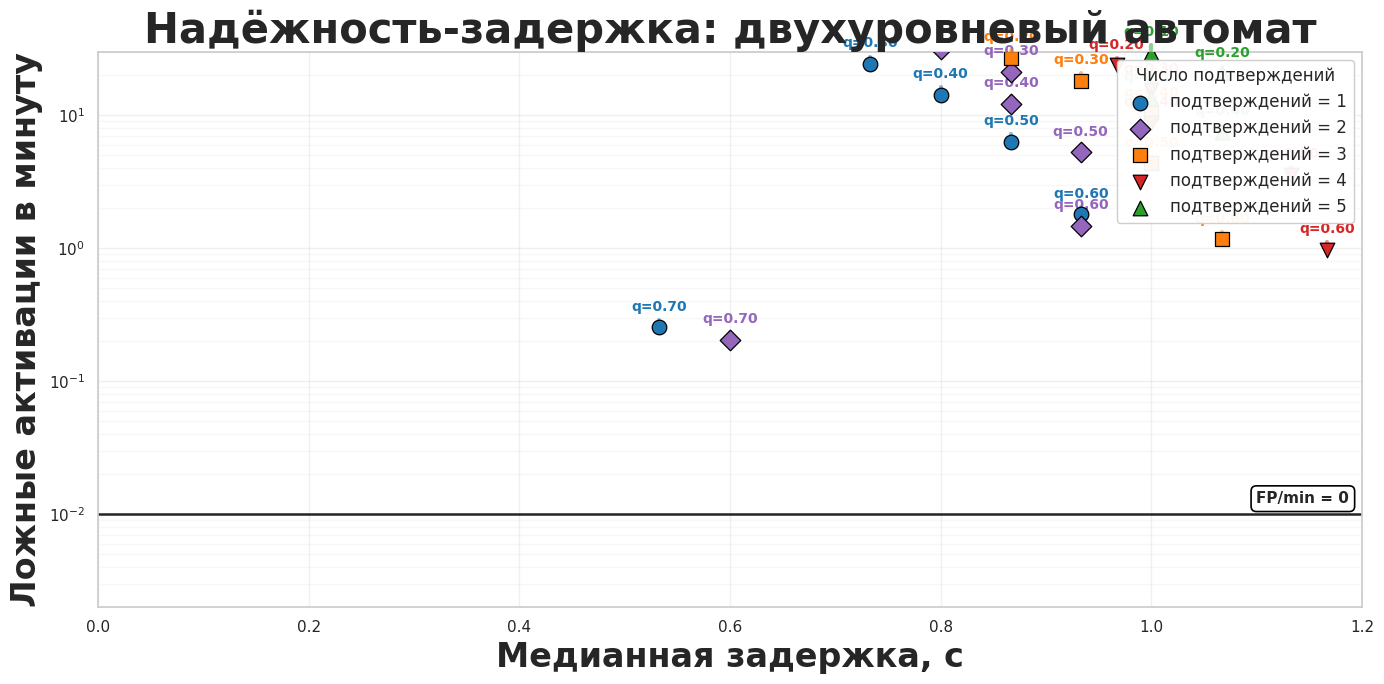

In [44]:
N_ACTIONS = len(CLASS_IDS)
N_SUBACTIONS = 2 * N_ACTIONS
X_train, y_train, _ = splits["train"]

with threadpool_limits(limits=2):
    one_vq = KMeans(n_clusters=N_ACTIONS, n_init=20, random_state=SEED).fit(X_train)
    sub_vq = KMeans(n_clusters=N_SUBACTIONS, n_init=20, random_state=SEED).fit(X_train)
    weights = np.bincount(sub_vq.labels_, minlength=N_SUBACTIONS)
    action_vq = KMeans(n_clusters=N_ACTIONS, n_init=20, random_state=SEED).fit(
        sub_vq.cluster_centers_, sample_weight=weights
    )

z_to_a = action_vq.labels_
one_map, _ = cm.fit_cluster_mapping(
    one_vq.labels_, y_train, N_ACTIONS, commands=CLASS_IDS
)
two_map, _ = cm.fit_cluster_mapping(
    z_to_a[sub_vq.labels_], y_train, N_ACTIONS, commands=CLASS_IDS
)


def kmeans_predict(split_name):
    # Ограничиваем временную матрицу расстояний, не меняя порядок окон.
    one_parts, two_parts, confidence_parts = [], [], []
    X = splits[split_name][0]
    with threadpool_limits(limits=2):
        for start in range(0, len(X), 8192):
            block = X[start:start + 8192]
            one_parts.append(cm.predict_one_level(block, one_map, one_vq))
            two, confidence = cm.predict_two_level(
                block, sub_vq, z_to_a, two_map, with_confidence=True,
                n_action_prototypes=N_ACTIONS,
            )
            two_parts.append(two)
            confidence_parts.append(confidence)

    return np.concatenate(one_parts), np.concatenate(two_parts), np.concatenate(confidence_parts)


kmeans_conf = kmeans_predict("conf")
kmeans_tuning, kmeans_params = tune_filters(*kmeans_conf)
plot_tuning(kmeans_tuning, "K-means")


,frame_accuracy,event_f1@10,event_f1@25,event_f1@50,event_precision,event_recall,false_activations_per_min,median_delay_s,p95_delay_s,double_commands_per_transition,missed_commands,reference_events,predicted_events,macro_f1
method,,,,,,,,,,,,,,
M1: K-means,0.173,0.068,0.044,0.024,0.013,0.119,63.908,0.6,1.800,0.173,3450,3917,34768,0.124
M2: K-means,0.170,0.078,0.051,0.027,0.015,0.115,54.624,0.8,1.933,0.127,3468,3917,29767,0.121
M3: K-means,0.174,0.061,0.039,0.022,0.012,0.112,66.315,0.6,1.533,0.160,3478,3917,36032,0.121
M4: K-means,0.159,0.086,0.060,0.033,0.038,0.030,5.591,1.0,1.800,0.002,3800,3917,3118,0.052


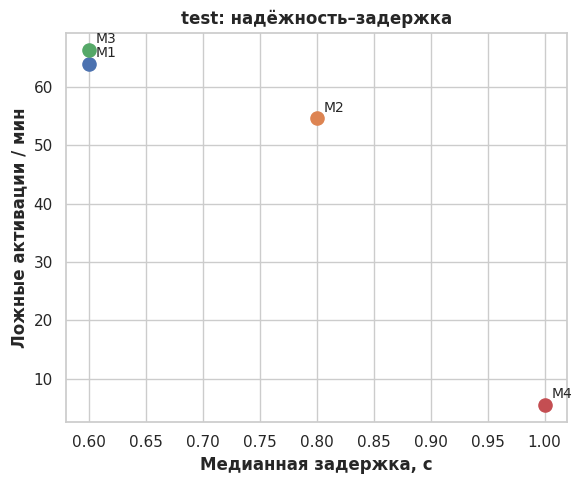

In [45]:
kmeans_test = kmeans_predict("test")
kmeans_predictions = make_predictions(*kmeans_test, "test", kmeans_params)
kmeans_comparison = comparison_table(kmeans_predictions, "K-means")

display(kmeans_comparison.set_index("method").round(3))
plot_results(kmeans_predictions, kmeans_comparison, "K-means")


## LSTM с каузальным attention: четыре метода

In [46]:
import random
import shutil
import subprocess

import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

LSTM_EPOCHS = 8
LSTM_BATCH_SIZE = 2
LSTM_HIDDEN_SIZE = 96
LSTM_ATTENTION_HEADS = 4
LSTM_ATTENTION_DROPOUT = 0.10
LSTM_LEARNING_RATE = 1e-3
LSTM_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.set_num_threads(2)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if LSTM_DEVICE.type == "cuda":
    print(f"Видеокарта: {torch.cuda.get_device_name(0)}.")
else:
    if shutil.which("nvidia-smi"):
        gpu_info = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
            capture_output=True, text=True, timeout=10, check=False,
        )

Видеокарта: NVIDIA GeForce GTX 1660 Ti.


In [47]:
class ManyToManyLSTM(nn.Module):
    def __init__(self, input_size, hidden_size, n_classes, n_layers,
                 attention_heads=4, attention_dropout=0.10):
        super().__init__()
        if attention_heads < 1 or hidden_size % attention_heads:
            raise ValueError("Размер скрытого состояния должен делиться на число голов attention.")

        self.attention_heads = attention_heads
        self.attention_dropout = attention_dropout
        self.qkv = nn.Linear(hidden_size, 3 * hidden_size)
        self.attention_out = nn.Linear(hidden_size, hidden_size)
        self.attention_norm = nn.LayerNorm(hidden_size)
        self.attention_residual_dropout = nn.Dropout(attention_dropout)

        self.lstm = nn.LSTM(
            input_size, hidden_size, num_layers=n_layers, batch_first=True,
            dropout=0.20 if n_layers > 1 else 0.0,
        )

        self.head = nn.Sequential(
            nn.Linear(hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, n_classes),
        )

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        packed_out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(
            packed_out, batch_first=True, total_length=x.shape[1]
        )

        batch_size, steps, hidden_size = out.shape
        head_size = hidden_size // self.attention_heads
        qkv = self.qkv(out).reshape(
            batch_size, steps, 3, self.attention_heads, head_size
        ).permute(2, 0, 3, 1, 4)
        query, key, value = qkv.unbind(dim=0)

        # Каждое окно видит только себя и предыдущие окна этой записи.
        # Padding справа недоступен настоящим окнам из-за каузальной маске.
        context = nn.functional.scaled_dot_product_attention(
            query, key, value, is_causal=True,
            dropout_p=self.attention_dropout if self.training else 0.0,
        )
        context = context.transpose(1, 2).reshape(batch_size, steps, hidden_size)
        out = self.attention_norm(
            out + self.attention_residual_dropout(self.attention_out(context))
        )
        logits = self.head(out)
        valid = torch.arange(steps, device=x.device)[None, :] < lengths.to(x.device)[:, None]
        return logits.masked_fill(~valid[:, :, None], 0.0)

In [48]:
def lstm_batches(records, *, shuffle=False, epoch=0):
    # Близкие длины уменьшают padding. Перемешиваем записи, но не окна внутри них.
    order = sorted(range(len(records)), key=lambda i: len(records[i][1]))
    batches = [order[i:i + LSTM_BATCH_SIZE] for i in range(0, len(order), LSTM_BATCH_SIZE)]
    if shuffle:
        np.random.default_rng(SEED + epoch).shuffle(batches)

    for indices in batches:
        batch = [records[i] for i in indices]
        lengths = torch.tensor([len(x) for _, x, _ in batch], dtype=torch.long)
        x_pad = torch.zeros(len(batch), int(lengths.max()), N_COMPONENTS, dtype=torch.float32)
        y_pad = torch.full((len(batch), int(lengths.max())), -100, dtype=torch.long)
        for i, (_, features, target) in enumerate(batch):
            x_pad[i, :len(features)] = torch.from_numpy(features)
            y_pad[i, :len(target)] = torch.from_numpy(target)

        yield x_pad.to(LSTM_DEVICE), y_pad.to(LSTM_DEVICE), lengths


train_counts = np.bincount(splits["train"][1], minlength=len(CLASS_IDS))
assert np.all(train_counts > 0)
class_weights = train_counts.sum() / (len(CLASS_IDS) * train_counts)
loss_weights = torch.tensor(class_weights, dtype=torch.float32, device=LSTM_DEVICE)


def train_lstm(n_layers):
    torch.manual_seed(SEED + n_layers)
    model = ManyToManyLSTM(
        N_COMPONENTS, LSTM_HIDDEN_SIZE, len(CLASS_IDS), n_layers,
        attention_heads=LSTM_ATTENTION_HEADS,
        attention_dropout=LSTM_ATTENTION_DROPOUT,
    ).to(LSTM_DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=LSTM_LEARNING_RATE, weight_decay=1e-4
    )
    criterion = nn.CrossEntropyLoss(weight=loss_weights, ignore_index=-100, reduction="sum")
    history, best_state, best_epoch = [], None, None
    best_loss = np.inf

    for epoch in range(LSTM_EPOCHS):
        row = {"epoch": epoch + 1}
        for split_name in ("train", "conf"):
            training = split_name == "train"
            model.train(training)
            loss_sum, weight_sum = 0.0, 0.0
            with torch.set_grad_enabled(training):
                for x, y, lengths in lstm_batches(
                    sequences[split_name], shuffle=training, epoch=epoch
                ):
                    if training:
                        optimizer.zero_grad(set_to_none=True)
                    logits = model(x, lengths)
                    batch_sum = criterion(logits.reshape(-1, len(CLASS_IDS)), y.reshape(-1))
                    normalizer = loss_weights[y[y != -100]].sum()
                    loss = batch_sum / normalizer

                    if training:
                        loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                        optimizer.step()

                    loss_sum += float(batch_sum.detach())
                    weight_sum += float(normalizer.detach())
            row[f"{split_name}_loss"] = loss_sum / weight_sum

        history.append(row)
        if row["conf_loss"] < best_loss:
            best_loss = row["conf_loss"]
            best_epoch = epoch + 1
            best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        print(
            f"LSTM, слоёв {n_layers}. Эпоха {epoch + 1}/{LSTM_EPOCHS}. "
            f"Train loss {row['train_loss']:.4f}. Conf loss {row['conf_loss']:.4f}."
        )

    if best_state is None:
        raise RuntimeError("Не получены конечные значения conf loss, проверьте признаки и обучение.")
    model.load_state_dict(best_state)
    # Между этапами держим веса на CPU, чтобы две сети не занимали GPU одновременно.
    model.to("cpu")
    print(f"Выбрана эпоха {best_epoch} по conf.")
    return model, pd.DataFrame(history)


lstm_one, history_one = train_lstm(n_layers=1)
lstm_two, history_two = train_lstm(n_layers=2)


LSTM, слоёв 1. Эпоха 1/8. Train loss 2.5824. Conf loss 1.9332.
LSTM, слоёв 1. Эпоха 2/8. Train loss 1.7561. Conf loss 1.6343.
LSTM, слоёв 1. Эпоха 3/8. Train loss 1.4883. Conf loss 1.5047.
LSTM, слоёв 1. Эпоха 4/8. Train loss 1.3220. Conf loss 1.4395.
LSTM, слоёв 1. Эпоха 5/8. Train loss 1.1928. Conf loss 1.3958.
LSTM, слоёв 1. Эпоха 6/8. Train loss 1.1095. Conf loss 1.3571.
LSTM, слоёв 1. Эпоха 7/8. Train loss 1.0284. Conf loss 1.3281.
LSTM, слоёв 1. Эпоха 8/8. Train loss 0.9599. Conf loss 1.3250.
Выбрана эпоха 8 по conf.
LSTM, слоёв 2. Эпоха 1/8. Train loss 2.5022. Conf loss 1.8481.
LSTM, слоёв 2. Эпоха 2/8. Train loss 1.6909. Conf loss 1.6094.
LSTM, слоёв 2. Эпоха 3/8. Train loss 1.4398. Conf loss 1.5001.
LSTM, слоёв 2. Эпоха 4/8. Train loss 1.2681. Conf loss 1.4289.
LSTM, слоёв 2. Эпоха 5/8. Train loss 1.1426. Conf loss 1.3994.
LSTM, слоёв 2. Эпоха 6/8. Train loss 1.0443. Conf loss 1.3382.
LSTM, слоёв 2. Эпоха 7/8. Train loss 0.9587. Conf loss 1.3173.
LSTM, слоёв 2. Эпоха 8/8. Trai

,epoch,train_loss,conf_loss
0,1,2.582352,1.933227
1,2,1.756130,1.634341
2,3,1.488260,1.504662
3,4,1.321958,1.439489
4,5,1.192798,1.395804
5,6,1.109539,1.357138
6,7,1.028442,1.328138
7,8,0.959854,1.324968


,epoch,train_loss,conf_loss
0,1,2.502242,1.848078
1,2,1.690947,1.609356
2,3,1.439849,1.500052
3,4,1.268130,1.428920
4,5,1.142585,1.399371
5,6,1.044295,1.338218
6,7,0.958655,1.317252
7,8,0.879373,1.332556


,window,confirmations,threshold,event_f1@50,false_activations_per_min
M2,5.0,NaN,NaN,0.162532,36.150277
M4,NaN,2.0,0.4,0.1745,10.611294


conf_baseline_f1@50    0.162532
conf_best_m4_f1@50     0.237057
conf_min_m4_f1@50      0.162532
event_f1@50              0.1745
Name: 20, dtype: object

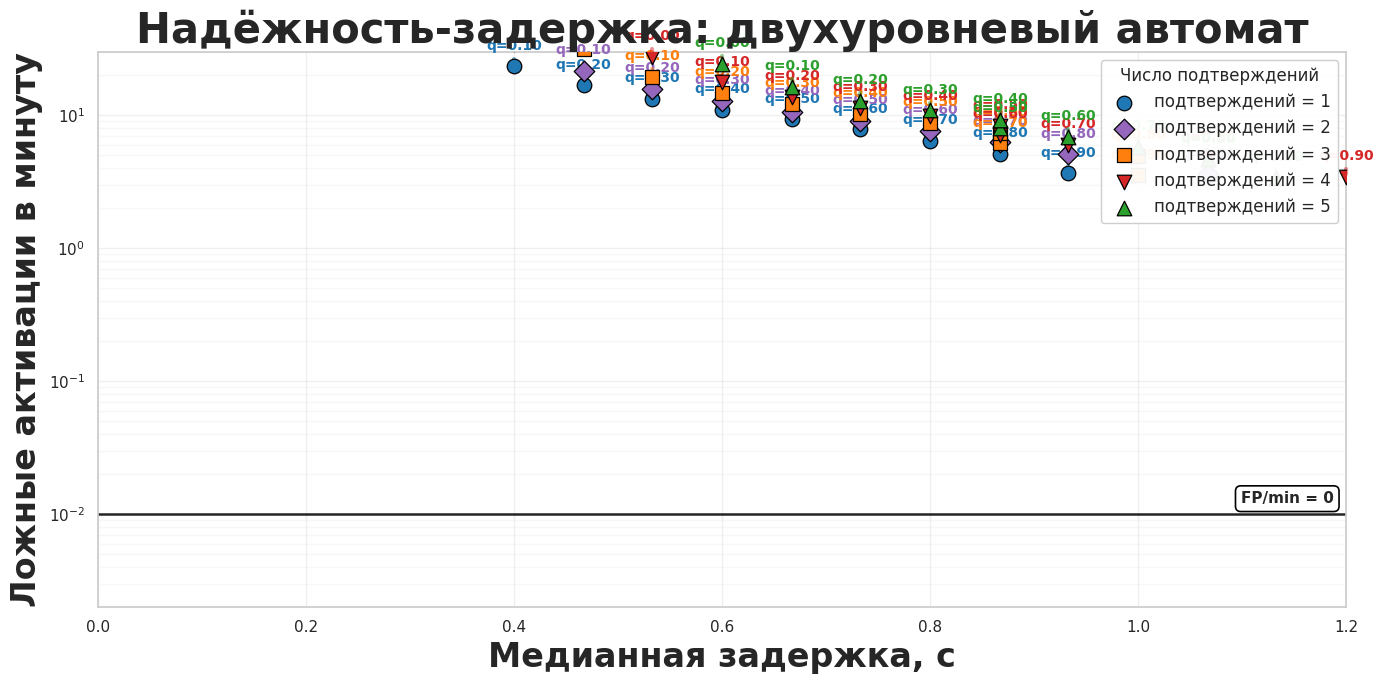

In [49]:
display(history_one)
display(history_two)

@torch.no_grad()
def lstm_predict(model, split_name):
    model.to(LSTM_DEVICE)
    model.eval()
    predictions, confidence = [], []
    for record_id, features, target in sequences[split_name]:
        x = torch.from_numpy(features).unsqueeze(0).to(LSTM_DEVICE)
        lengths = torch.tensor([len(features)], dtype=torch.long)
        logits = model(x, lengths).squeeze(0)
        probabilities = logits.softmax(dim=-1)
        top_two = probabilities.topk(k=2, dim=-1).values
        predictions.append(logits.argmax(dim=-1).cpu().numpy())
        confidence.append((top_two[:, 0] - top_two[:, 1]).cpu().numpy())

    model.to("cpu")
    return np.concatenate(predictions), np.concatenate(confidence)


lstm_one_conf, _ = lstm_predict(lstm_one, "conf")
lstm_two_conf, lstm_confidence_conf = lstm_predict(lstm_two, "conf")
lstm_tuning, lstm_params = tune_filters(
    lstm_one_conf, lstm_two_conf, lstm_confidence_conf
)
plot_tuning(lstm_tuning, "LSTM")


,frame_accuracy,event_f1@10,event_f1@25,event_f1@50,event_precision,event_recall,false_activations_per_min,median_delay_s,p95_delay_s,double_commands_per_transition,missed_commands,reference_events,predicted_events,macro_f1
method,,,,,,,,,,,,,,
M1: LSTM,0.560,0.229,0.212,0.155,0.089,0.584,43.502,0.333,2.000,0.230,1629,3917,25637,0.508
M2: LSTM,0.551,0.276,0.254,0.178,0.106,0.556,34.174,0.400,2.067,0.159,1741,3917,20518,0.496
M3: LSTM,0.523,0.244,0.223,0.163,0.095,0.584,40.712,0.333,1.933,0.174,1630,3917,24138,0.499
M4: LSTM,0.312,0.557,0.433,0.186,0.147,0.250,10.544,0.600,2.333,0.009,2938,3917,6638,0.376


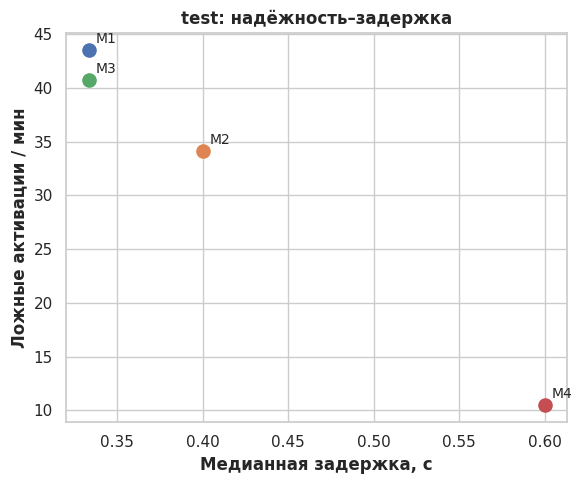

In [50]:
lstm_one_test, _ = lstm_predict(lstm_one, "test")
lstm_two_test, lstm_confidence_test = lstm_predict(lstm_two, "test")
lstm_predictions = make_predictions(
    lstm_one_test, lstm_two_test, lstm_confidence_test, "test", lstm_params
)
lstm_comparison = comparison_table(lstm_predictions, "LSTM")

display(lstm_comparison.set_index("method").round(3))
plot_results(lstm_predictions, lstm_comparison, "LSTM")


## Общая таблица

Все восемь строк используют одинаковый test. Порог основной событийной оценки - **IoU 0,50**. Для F1 дополнительно оставлены IoU 0,10 и 0,25, как в других экспериментах проекта.

На графике переключений сравниваем **M3 и M4**, то есть вход автомата и его выход. Переходы в фон и из фона считаются сменой выходной метки. Внутреннее состояние TRANSITION в этот счётчик не попадает.

Пример берётся из первой test-записи, без поиска самого удачного фрагмента.


In [51]:
comparison = pd.concat([kmeans_comparison, lstm_comparison], ignore_index=True)
display(comparison.set_index("method").round(3))



,frame_accuracy,event_f1@10,event_f1@25,event_f1@50,event_precision,event_recall,false_activations_per_min,median_delay_s,p95_delay_s,double_commands_per_transition,missed_commands,reference_events,predicted_events,macro_f1
method,,,,,,,,,,,,,,
M1: K-means,0.173,0.068,0.044,0.024,0.013,0.119,63.908,0.600,1.800,0.173,3450,3917,34768,0.124
M2: K-means,0.170,0.078,0.051,0.027,0.015,0.115,54.624,0.800,1.933,0.127,3468,3917,29767,0.121
M3: K-means,0.174,0.061,0.039,0.022,0.012,0.112,66.315,0.600,1.533,0.160,3478,3917,36032,0.121
M4: K-means,0.159,0.086,0.060,0.033,0.038,0.030,5.591,1.000,1.800,0.002,3800,3917,3118,0.052
M1: LSTM,0.560,0.229,0.212,0.155,0.089,0.584,43.502,0.333,2.000,0.230,1629,3917,25637,0.508
M2: LSTM,0.551,0.276,0.254,0.178,0.106,0.556,34.174,0.400,2.067,0.159,1741,3917,20518,0.496
M3: LSTM,0.523,0.244,0.223,0.163,0.095,0.584,40.712,0.333,1.933,0.174,1630,3917,24138,0.499
M4: LSTM,0.312,0.557,0.433,0.186,0.147,0.250,10.544,0.600,2.333,0.009,2938,3917,6638,0.376


## Проверки каузальности и сброса состояния

In [52]:
rng = np.random.default_rng(SEED)
probe_labels = rng.choice(CLASS_IDS, size=80)
probe_confidence = rng.uniform(size=80)

for family, params in (("K-means", kmeans_params), ("LSTM", lstm_params)):
    assert cm.assert_causal(
        probe_labels, probe_confidence,
        params["confirmations"], params["threshold"], **FSM_PARAMS,
    )
    full = cm.causal_majority(probe_labels, params["window"])
    for end in (1, 7, 31, 80):
        prefix = cm.causal_majority(probe_labels[:end], params["window"])
        np.testing.assert_array_equal(prefix, full[:end])

    parts = [slice(0, 37), slice(37, 80)]
    combined, _ = cm.apply_per_record(
        probe_labels, parts,
        lambda x, c: cm.transition_automaton(
            x, c, params["confirmations"], params["threshold"], **FSM_PARAMS
        ),
        probe_confidence,
    )
    separate = np.concatenate([
        cm.transition_automaton(
            probe_labels[sl], probe_confidence[sl],
            params["confirmations"], params["threshold"], **FSM_PARAMS,
        )[0]
        for sl in parts
    ])
    np.testing.assert_array_equal(combined, separate)

# Низкая уверенность удерживает подтверждённый класс, не создаёт новый.
held, _ = cm.transition_automaton(
    np.array([1, 2, 2]), np.array([1.0, 0.0, 0.0]), 1, 0.5, **FSM_PARAMS
)
np.testing.assert_array_equal(held, [1, 1, 1])

with torch.no_grad():
    probe = torch.from_numpy(rng.normal(size=(1, 20, N_COMPONENTS)).astype(np.float32))
    for model in (lstm_one, lstm_two):
        model.to("cpu").eval()
        full = model(probe, torch.tensor([20]))
        for end in (1, 7, 13):
            prefix = model(probe[:, :end], torch.tensor([end]))
            torch.testing.assert_close(prefix, full[:, :end], rtol=1e-4, atol=1e-5)

        # Другая запись и padding в батче не должны влиять на первую запись.
        batch = torch.cat([probe, torch.randn_like(probe)], dim=0)
        batched = model(batch, torch.tensor([7, 20]))
        alone = model(probe[:, :7], torch.tensor([7]))
        torch.testing.assert_close(batched[:1, :7], alone, rtol=1e-4, atol=1e-5)

print("Проверки пройдены. Будущие окна не меняют прошлые выходы, записи обрабатываются независимо.")


Проверки пройдены. Будущие окна не меняют прошлые выходы, записи обрабатываются независимо.
